In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet, HuberRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [16]:
RANDOM_STATE = 42
FORECAST_END = 2030
BASE_SCENARIO = 0.10
SCENARIOS = [0.0, BASE_SCENARIO]
IMPORT_SUBSTITUTION_PASS_THROUGH = 1.0

SECTORS = {
    'Agriculture': 'DATA_Agriculture',
    'Fertilizers': 'DATA_Fertilizers',
    'Iron & Steel': 'DATA_Iron_&_Steel'
}

INPUT_FILE = Path('/content/EGYPT_2030_FINAL_ALL_YEARS_MODEL.xlsx')
OUTPUT_FILE = Path('/content/EGYPT_2030_ONLY_FINAL.xlsx')

In [17]:

from pathlib import Path
import pandas as pd
import numpy as np

INPUT_FILE = Path(
    "/content/EGYPT_2030_FINAL_ALL_YEARS_MODEL.xlsx"
)

OUTPUT_FILE = Path(
    "/content/EGYPT_2030_IMPROVED_FINAL.xlsx"
)

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"File not found: {INPUT_FILE}"
    )

print("Excel file found.")
print(INPUT_FILE)

# Test Excel before running the model
xls = pd.ExcelFile(INPUT_FILE)

print("\nAvailable sheets:")
for sheet in xls.sheet_names:
    print(" -", sheet)

print("\nExcel loading test completed.")

Excel file found.
/content/EGYPT_2030_FINAL_ALL_YEARS_MODEL.xlsx

Available sheets:
 - FINAL_RESULTS
 - MODEL_COMPARISON
 - PARTNERS_Agriculture
 - PARTNERS_Fertilizers
 - PARTNERS_Iron_&_Steel
 - EXPORT_OPPORTUNITY
 - DATA_Agriculture
 - DATA_Fertilizers
 - DATA_Iron_&_Steel
 - SOURCES
 - EXECUTIVE

Excel loading test completed.


In [5]:
def load_sector_data(sector, sheet):
    df = pd.read_excel(INPUT_FILE, sheet_name=sheet)
    required = {'year', 'production_t', 'imports_usd'}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f'{sector}: missing columns {sorted(missing)}')

    keep = ['year', 'production_t', 'imports_usd']
    # Keep optional fields if available; they are useful for diagnostics.
    for c in ['exports_usd', 'exports_t', 'imports_t']:
        if c in df.columns:
            keep.append(c)

    df = df[keep].copy()
    for c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

    df = (
        df.dropna(subset=['year', 'production_t', 'imports_usd'])
          .drop_duplicates('year')
          .sort_values('year')
          .reset_index(drop=True)
    )
    df = df[(df['production_t'] >= 0) & (df['imports_usd'] >= 0)].copy()
    return df

sector_data = {
    sector: load_sector_data(sector, sheet)
    for sector, sheet in SECTORS.items()
}

data_quality_rows = []
for sector, df in sector_data.items():
    data_quality_rows.append({
        'Sector': sector,
        'Start_Year': int(df.year.min()),
        'End_Year': int(df.year.max()),
        'N_Years': len(df),
        'Status': 'LOW_SAMPLE' if len(df) < 8 else 'OK',
        'Warning': 'Use with caution; short time series' if len(df) < 8 else ''
    })

In [6]:
FEATURES = [
    'year', 'trend', 'production_t', 'log_production',
    'production_growth', 'lag_imports', 'lag2_imports',
    'lag_production', 'log_lag_imports'
]

def make_features(df):
    x = df.copy()
    x['trend'] = np.arange(len(x), dtype=float)
    x['production_growth'] = x['production_t'].pct_change()
    x['lag_imports'] = x['imports_usd'].shift(1)
    x['lag2_imports'] = x['imports_usd'].shift(2)
    x['lag_production'] = x['production_t'].shift(1)
    x['log_production'] = np.log1p(x['production_t'])
    x['log_lag_imports'] = np.log1p(x['lag_imports'])
    return x

featured_data = {sector: make_features(df) for sector, df in sector_data.items()}
display(featured_data['Agriculture'].tail())

,year,production_t,imports_usd,trend,production_growth,lag_imports,lag2_imports,lag_production,log_production,log_lag_imports
1,2020,15502000,5.222948e+09,1.0,0.036299,4.960154e+09,NaN,14959000.0,16.556480,22.324703
2,2021,17282000,6.341229e+09,2.0,0.114824,5.222948e+09,4.960154e+09,15502000.0,16.665176,22.376328
3,2022,16940000,7.322105e+09,3.0,-0.019789,6.341229e+09,5.222948e+09,17282000.0,16.645188,22.570338
4,2023,16070000,6.229439e+09,4.0,-0.051358,7.322105e+09,6.341229e+09,16940000.0,16.592465,22.714164
5,2024,16200000,6.743166e+09,5.0,0.008090,6.229439e+09,7.322105e+09,16070000.0,16.600522,22.552552


In [7]:
def candidate_models(n_train):
    models = {
        'NaiveLastImport': None,

        'Ridge': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', Ridge(alpha=10.0))
        ]),

        'ElasticNet': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', ElasticNet(
                alpha=0.01,
                l1_ratio=0.20,
                max_iter=20000,
                random_state=RANDOM_STATE
            ))
        ])
    }

    # Huber needs a little more data to be meaningful.
    if n_train >= 5:
        models['Huber'] = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', HuberRegressor(
                epsilon=1.35,
                alpha=0.1,
                max_iter=1000
            ))
        ])

    # Tree models are intentionally restricted to larger samples.
    if n_train >= 12:
        models['RandomForest'] = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('model', RandomForestRegressor(
                n_estimators=500,
                max_depth=3,
                min_samples_leaf=2,
                max_features=0.8,
                random_state=RANDOM_STATE
            ))
        ])

        models['ExtraTrees'] = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('model', ExtraTreesRegressor(
                n_estimators=500,
                max_depth=3,
                min_samples_leaf=2,
                max_features=0.8,
                random_state=RANDOM_STATE
            ))
        ])

    return models


In [8]:
def walk_forward_splits(n):
    # One-step-ahead expanding-window validation.
    # For very short series, all feasible splits are used.
    if n < 3:
        return []
    return [(np.arange(0, i), np.array([i])) for i in range(2, n)]


def safe_metrics(actual, pred):
    actual = np.asarray(actual, dtype=float)
    pred = np.asarray(pred, dtype=float)

    mae = mean_absolute_error(actual, pred)
    rmse = float(np.sqrt(mean_squared_error(actual, pred)))

    nonzero = actual != 0
    if nonzero.any():
        mape = float(
            np.mean(
                np.abs(
                    (actual[nonzero] - pred[nonzero])
                    / actual[nonzero]
                )
            ) * 100
        )
    else:
        mape = np.nan

    return mae, rmse, mape


def fit_best_model(df):
    f = make_features(df)

    # Only lag-1 is mandatory. Lag-2 can be imputed when the sample is short.
    f_ml = (
        f.dropna(subset=['lag_imports', 'lag_production'])
         .reset_index(drop=True)
    )

    X = f_ml[FEATURES].copy()
    y = np.log1p(f_ml['imports_usd'].clip(lower=0))

    if len(f_ml) < 2:
        raise ValueError(
            'Not enough observations for a supervised import model.'
        )

    splits = walk_forward_splits(len(f_ml))
    candidates = candidate_models(len(f_ml))
    rows = []

    for name, model in candidates.items():

        actual_all = []
        pred_all = []

        # If the series is too short, NaiveLastImport is the only defensible
        # model. Other models are skipped rather than pretending to have accuracy.
        if name != 'NaiveLastImport' and len(splits) == 0:
            continue

        for train_idx, test_idx in splits:

            actual = float(
                np.expm1(y.iloc[test_idx[0]])
            )

            if name == 'NaiveLastImport':

                pred = float(
                    f_ml.iloc[train_idx[-1]]['imports_usd']
                )

            else:

                m = clone(model)

                try:
                    m.fit(
                        X.iloc[train_idx],
                        y.iloc[train_idx]
                    )

                    pred = float(
                        np.expm1(
                            m.predict(X.iloc[test_idx])[0]
                        )
                    )

                except Exception:
                    pred = float(
                        f_ml.iloc[train_idx[-1]]['imports_usd']
                    )

                pred = max(pred, 0.0)

            actual_all.append(actual)
            pred_all.append(pred)

        if actual_all:

            mae, rmse, mape = safe_metrics(
                actual_all,
                pred_all
            )

            rows.append({
                'Model': name,
                'CV_MAE_USD': mae,
                'CV_RMSE_USD': rmse,
                'CV_MAPE_pct': mape
            })

    scores_df = (
        pd.DataFrame(rows)
        .sort_values(
            ['CV_MAE_USD', 'CV_RMSE_USD']
        )
        .reset_index(drop=True)
    )

    if scores_df.empty:
        best_name = 'NaiveLastImport'
        best_model = None
    else:
        best_name = scores_df.iloc[0]['Model']

        if best_name == 'NaiveLastImport':
            best_model = None
        else:
            best_model = clone(
                candidates[best_name]
            )

            try:
                best_model.fit(X, y)
            except Exception:
                best_name = 'NaiveLastImport'
                best_model = None

    return {
        'features': f,
        'train_features': f_ml,
        'X': X,
        'y': y,
        'scores': scores_df,
        'best_name': best_name,
        'best_model': best_model
    }


fitted = {}
validation_tables = []

for sector, df in sector_data.items():

    fitted[sector] = fit_best_model(df)

    s = fitted[sector]['scores'].copy()

    s.insert(
        0,
        'Sector',
        sector
    )

    s['Selected'] = (
        s['Model']
        .eq(fitted[sector]['best_name'])
    )

    validation_tables.append(s)

    print(
        f'\n{sector} → '
        f'{fitted[sector]["best_name"]}'
    )

    display(s)



Agriculture → Ridge


,Sector,Model,CV_MAE_USD,CV_RMSE_USD,CV_MAPE_pct,Selected
0,Agriculture,Ridge,6.312017e+08,8.152719e+08,9.863410,True
1,Agriculture,NaiveLastImport,8.624223e+08,8.981366e+08,12.851635,False
2,Agriculture,ElasticNet,1.299603e+09,1.341996e+09,19.612626,False
3,Agriculture,Huber,1.365772e+09,1.393735e+09,20.544709,False



Fertilizers → NaiveLastImport


,Sector,Model,CV_MAE_USD,CV_RMSE_USD,CV_MAPE_pct,Selected
0,Fertilizers,NaiveLastImport,5.311028e+07,5.311028e+07,14.541205,True
1,Fertilizers,Ridge,6.883098e+08,6.883098e+08,188.454170,False
2,Fertilizers,ElasticNet,2.017672e+09,2.017672e+09,552.423677,False



Iron & Steel → NaiveLastImport


,Sector,Model,CV_MAE_USD,CV_RMSE_USD,CV_MAPE_pct,Selected
0,Iron & Steel,NaiveLastImport,4.686304e+08,5.258733e+08,42.095949,True
1,Iron & Steel,Ridge,5.036638e+08,5.864462e+08,44.759649,False
2,Iron & Steel,ElasticNet,5.147361e+08,5.809921e+08,47.583674,False
3,Iron & Steel,Huber,5.280662e+08,5.991393e+08,48.282238,False


In [9]:
def production_growth_assumption(df):
    g = df['production_t'].pct_change().dropna()
    if len(g) == 0:
        return 0.0
    recent = float(g.tail(min(3, len(g))).median())
    if len(g) >= 4:
        lo, hi = np.quantile(g, [0.10, 0.90])
        lo = min(lo, -0.10)
        hi = max(hi, 0.10)
    else:
        lo, hi = -0.10, 0.10
    return float(np.clip(recent, lo, hi))


def forecast_production(df, end_year=FORECAST_END):
    # Intermediate years are needed internally to reach 2030,
    # but only 2030 is returned to the rest of the model.
    last_year = int(df['year'].max())
    growth = production_growth_assumption(df)
    current = float(df.iloc[-1]['production_t'])

    rows = []
    for year in range(last_year + 1, end_year + 1):
        current *= (1 + growth)
        rows.append({
            'year': year,
            'baseline_production_t': current,
             'production_growth_assumption': growth
        })

    future = pd.DataFrame(rows)

    if future.empty:
        raise ValueError(f"No future year available for {end_year}.")

    # 2030 ONLY
    return future[future['year'].eq(end_year)].reset_index(drop=True)


production_forecasts = {
    sector: forecast_production(df)
    for sector, df in sector_data.items()
}

for sector, pf in production_forecasts.items():
    print(f'\n{sector} — 2030 production forecast only')
    display(pf)



Agriculture — 2030 production forecast only


,year,baseline_production_t,production_growth_assumption
0,2030,1.436916e+07,-0.019789



Fertilizers — 2030 production forecast only


,year,baseline_production_t,production_growth_assumption
0,2030,1.409519e+07,0.023256



Iron & Steel — 2030 production forecast only


,year,baseline_production_t,production_growth_assumption
0,2030,1.269072e+07,0.028846


In [12]:
def make_future_features(
    year,
    trend,
    production,
    last_production,
    prev_production,
    lag_imports,
    lag2_imports
):
    return pd.DataFrame([{
        'year': year,
        'trend': trend,
        'production_t': production,
        'log_production': np.log1p(max(production, 0)),
        'production_growth': production / max(last_production, 1) - 1,
        'lag_imports': lag_imports,
        'lag2_imports': lag2_imports,
        'lag_production': last_production,
        'log_lag_imports': np.log1p(max(lag_imports, 0))
    }])[FEATURES]


def recursive_ml_forecast(df, info, production_path):

    hist = df.sort_values('year').copy()

    lag_imports = float(
        hist.iloc[-1]['imports_usd']
    )

    lag2_imports = (
        float(hist.iloc[-2]['imports_usd'])
        if len(hist) >= 2
        else lag_imports
    )

    last_production = float(
        hist.iloc[-1]['production_t']
    )

    prev_production = (
        float(hist.iloc[-2]['production_t'])
        if len(hist) >= 2
        else last_production
    )

    trend = len(hist)

    rows = []

    for _, r in production_path.iterrows():

        Xf = make_future_features(
            int(r['year']),
            trend,
            float(r['baseline_production_t']),
            last_production,
            prev_production,
            lag_imports,
            lag2_imports
        )

        if info['best_name'] == 'NaiveLastImport':

            pred_imports = lag_imports

        else:

            pred_imports = float(
                np.expm1(
                    info['best_model'].predict(Xf)[0]
                )
            )

            pred_imports = max(
                pred_imports,
                0.0
            )

        rows.append({
            'year': int(r['year']),
            'baseline_production_t': float(
                r['baseline_production_t']
            ),
            'baseline_imports_ml_usd': pred_imports
        })

        lag2_imports, lag_imports = (
            lag_imports,
            pred_imports
        )

        prev_production, last_production = (
            last_production,
            float(r['baseline_production_t'])
        )

        trend += 1

    return pd.DataFrame(rows)


baseline_forecasts = {}

for sector, df in sector_data.items():

    baseline_forecasts[sector] = recursive_ml_forecast(
        df,
        fitted[sector],
        production_forecasts[sector]
    )

    print(f'\n{sector}')
    display(baseline_forecasts[sector])



Agriculture


,year,baseline_production_t,baseline_imports_ml_usd
0,2030,1.436916e+07,6.293665e+09



Fertilizers


,year,baseline_production_t,baseline_imports_ml_usd
0,2030,1.409519e+07,365239873.0



Iron & Steel


,year,baseline_production_t,baseline_imports_ml_usd
0,2030,1.269072e+07,1.476541e+09


In [18]:
scenario_rows = []

for sector, bf in baseline_forecasts.items():
    for _, r in bf.iterrows():
        # bf contains 2030 only
        for shock in SCENARIOS:
            baseline_imports = float(r['baseline_imports_ml_usd'])

            displacement = min(
                baseline_imports,
                baseline_imports * shock * IMPORT_SUBSTITUTION_PASS_THROUGH
            )

            scenario_imports = max(
                baseline_imports - displacement,
                0.0
            )

            scenario_production = (
                float(r['baseline_production_t']) * (1 + shock)
            )

            scenario_rows.append({
                'Sector': sector,
                'Year': 2030,
                'Production_Shock_pct': shock * 100,
                'Baseline_Production_t': float(r['baseline_production_t']),
                'Scenario_Production_t': scenario_production,
                'Baseline_Imports_USD': baseline_imports,
                'Import_Displacement_USD': displacement,
                'Scenario_Imports_USD': scenario_imports,
                'FX_Savings_USD': displacement,
                'Import_Reduction_pct':
                    100 * displacement / baseline_imports
                    if baseline_imports else np.nan
            })

scenario_df = pd.DataFrame(scenario_rows)

# Keep 2030 only
scenario_df = scenario_df[
    scenario_df['Year'].eq(2030)
].copy()

base_10_df = scenario_df[
    scenario_df['Production_Shock_pct'].eq(BASE_SCENARIO * 100)
].copy()

display(base_10_df)

,Sector,Year,Production_Shock_pct,Baseline_Production_t,Scenario_Production_t,Baseline_Imports_USD,Import_Displacement_USD,Scenario_Imports_USD,FX_Savings_USD,Import_Reduction_pct
1,Agriculture,2030,10.0,1.436916e+07,1.580608e+07,6.293665e+09,6.293665e+08,5.664299e+09,6.293665e+08,10.0
3,Fertilizers,2030,10.0,1.409519e+07,1.550470e+07,3.652399e+08,3.652399e+07,3.287159e+08,3.652399e+07,10.0
5,Iron & Steel,2030,10.0,1.269072e+07,1.395980e+07,1.476541e+09,1.476541e+08,1.328887e+09,1.476541e+08,10.0


In [19]:
PARTNER_SHEETS = {
    'Agriculture': 'PARTNERS_Agriculture',
    'Fertilizers': 'PARTNERS_Fertilizers',
    'Iron & Steel': 'PARTNERS_Iron_&_Steel'
}

def load_partner_data(sector):
    sheet = PARTNER_SHEETS.get(sector)
    if sheet not in pd.ExcelFile(INPUT_FILE).sheet_names:
        return pd.DataFrame(columns=['Partner', 'Import_USD'])
    q = pd.read_excel(INPUT_FILE, sheet_name=sheet)
    partner_col = next((c for c in q.columns if str(c).lower() in ['partner', 'country', 'supplier', 'exporter']), None)
    value_col = next((c for c in q.columns if str(c).lower() in ['import_usd', 'imports_usd', 'value_usd', 'trade_value']), None)
    if partner_col is None or value_col is None:
        return pd.DataFrame(columns=['Partner', 'Import_USD'])
    q = q[[partner_col, value_col]].copy()
    q.columns = ['Partner', 'Import_USD']
    q['Import_USD'] = pd.to_numeric(q['Import_USD'], errors='coerce')
    return q.dropna().query('Import_USD >= 0')

partner_outputs = {}
latest_base = base_10_df.sort_values('Year').groupby('Sector').tail(1).set_index('Sector')

for sector in SECTORS:
    q = load_partner_data(sector)
    if q.empty:
        partner_outputs[sector] = q
        print(f'{sector}: partner data unavailable')
        continue
    total = q['Import_USD'].sum()
    savings = float(latest_base.loc[sector, 'FX_Savings_USD']) if sector in latest_base.index else 0.0
    q['Share_pct'] = np.where(total > 0, q['Import_USD'] / total * 100, 0)
    q['Estimated_Import_Displacement_USD'] = q['Share_pct'] / 100 * savings
    q['Scenario_Imports_USD'] = np.maximum(q['Import_USD'] - q['Estimated_Import_Displacement_USD'], 0)
    q['Import_Change_pct'] = np.where(q['Import_USD'] > 0, -q['Estimated_Import_Displacement_USD'] / q['Import_USD'] * 100, 0)
    partner_outputs[sector] = q.sort_values('Import_USD', ascending=False)
    print(f'\n{sector}')
    display(partner_outputs[sector].head(15))


Agriculture


,Partner,Import_USD,Share_pct,Estimated_Import_Displacement_USD,Scenario_Imports_USD,Import_Change_pct
0,Russian Federation,3.058846e+09,45.362167,2.854943e+08,2.773352e+09,-9.333398
1,Ukraine,1.465091e+09,21.727051,1.367428e+08,1.328348e+09,-9.333398
2,Brazil,1.138841e+09,16.888825,1.062926e+08,1.032549e+09,-9.333398
3,Romania,2.933658e+08,4.350565,2.738100e+07,2.659848e+08,-9.333398
4,Argentina,2.304810e+08,3.417994,2.151171e+07,2.089693e+08,-9.333398
5,France,1.825917e+08,2.707804,1.704201e+07,1.655497e+08,-9.333398
6,Bulgaria,1.766003e+08,2.618952,1.648281e+07,1.601175e+08,-9.333398
7,USA,7.752020e+07,1.149611,7.235269e+06,7.028493e+07,-9.333398
8,Australia,5.444704e+07,0.807440,5.081759e+06,4.936528e+07,-9.333398
9,Rep. of Moldova,2.097281e+07,0.311023,1.957476e+06,1.901534e+07,-9.333398



Fertilizers


,Partner,Import_USD,Share_pct,Estimated_Import_Displacement_USD,Scenario_Imports_USD,Import_Change_pct
0,Jordan,107954259,34.214671,1.249656e+07,9.545770e+07,-11.575794
1,Russia,32785034,10.390782,3.795128e+06,2.898991e+07,-11.575794
2,China,31115408,9.861616,3.601855e+06,2.751355e+07,-11.575794
3,Belgium,29347193,9.301204,3.397171e+06,2.595002e+07,-11.575794
4,Spain,27043783,8.571169,3.130533e+06,2.391325e+07,-11.575794
5,Norway,20235662,6.413425,2.342438e+06,1.789322e+07,-11.575794
6,Turkey,12345721,3.912813,1.429115e+06,1.091661e+07,-11.575794
7,Chile,7993503,2.533435,9.253114e+05,7.068192e+06,-11.575794
8,Italy,7307603,2.316048,8.459130e+05,6.461690e+06,-11.575794
9,Germany,6737402,2.135330,7.799078e+05,5.957494e+06,-11.575794



Iron & Steel


,Partner,Import_USD,Share_pct,Estimated_Import_Displacement_USD,Scenario_Imports_USD,Import_Change_pct
0,Russian Federation,7.664490e+08,51.908418,7.664490e+07,6.898041e+08,-10.0
1,China,1.978660e+08,13.400644,1.978660e+07,1.780794e+08,-10.0
2,Ukraine,1.603644e+08,10.860816,1.603644e+07,1.443279e+08,-10.0
3,Indonesia,1.023452e+08,6.931419,1.023452e+07,9.211070e+07,-10.0
4,Türkiye,9.440689e+07,6.393788,9.440689e+06,8.496620e+07,-10.0
5,Oman,5.325267e+07,3.606583,5.325267e+06,4.792740e+07,-10.0
6,Libya,3.898172e+07,2.640071,3.898172e+06,3.508355e+07,-10.0
7,United Arab Emirates,2.743855e+07,1.858299,2.743855e+06,2.469469e+07,-10.0
8,"Other Asia, nes",1.283642e+07,0.869357,1.283642e+06,1.155278e+07,-10.0
9,Bahrain,9.658555e+06,0.654134,9.658555e+05,8.692700e+06,-10.0


In [20]:
def indicative_import_value_per_ton(df):
    # This is NOT a true import unit price because import quantities are not available.
    # It is only an indicative USD-per-domestic-production-ton intensity.
    last = df.iloc[-1]
    return float(last['imports_usd'] / max(last['production_t'], 1))

export_rows = []

for sector, df in sector_data.items():
    r = base_10_df[base_10_df['Sector'].eq(sector)].sort_values('Year').iloc[-1]
    displacement_usd = float(r['Import_Displacement_USD'])
    intensity = indicative_import_value_per_ton(df)
    displacement_t = displacement_usd / max(intensity, 1e-9)
    incremental_production_t = float(r['Scenario_Production_t'] - r['Baseline_Production_t'])
    exportable_surplus_t = max(incremental_production_t - displacement_t, 0.0)
    export_value = exportable_surplus_t * intensity

    export_rows.append({
        'Sector': sector,
        'Year': int(r['Year']),
        'Incremental_Production_t': incremental_production_t,
        'Estimated_Import_Displacement_t': displacement_t,
        'Exportable_Surplus_t': exportable_surplus_t,
        'Indicative_USD_per_t': intensity,
        'Potential_Export_Value_USD': export_value,
        'Note': 'Indicative only because import quantity/export quantity are not available.'
    })

export_df = pd.DataFrame(export_rows)
display(export_df)

,Sector,Year,Incremental_Production_t,Estimated_Import_Displacement_t,Exportable_Surplus_t,Indicative_USD_per_t,Potential_Export_Value_USD,Note
0,Agriculture,2030,1.436916e+06,1.512011e+06,0.000000,416.244791,0.000000e+00,Indicative only because import quantity/export...
1,Fertilizers,2030,1.409519e+06,1.200000e+06,209518.538986,30.436656,6.377044e+06,Indicative only because import quantity/export...
2,Iron & Steel,2030,1.269072e+06,1.070000e+06,199072.426009,137.994467,2.747089e+07,Indicative only because import quantity/export...


In [21]:
trade_rows = []
for sector, df in sector_data.items():
    r = base_10_df[base_10_df['Sector'].eq(sector)].sort_values('Year').iloc[-1]
    exp = export_df[export_df['Sector'].eq(sector)].iloc[0]
    trade_rows.append({
        'Sector': sector,
        'Year': int(r['Year']),
        'Import_Reduction_USD': float(r['FX_Savings_USD']),
        'Potential_Export_Value_USD': float(exp['Potential_Export_Value_USD']),
        'Potential_Trade_Balance_Improvement_USD': float(r['FX_Savings_USD'] + exp['Potential_Export_Value_USD'])
    })

trade_df = pd.DataFrame(trade_rows)
display(trade_df)

,Sector,Year,Import_Reduction_USD,Potential_Export_Value_USD,Potential_Trade_Balance_Improvement_USD
0,Agriculture,2030,6.293665e+08,0.000000e+00,6.293665e+08
1,Fertilizers,2030,3.652399e+07,6.377044e+06,4.290103e+07
2,Iron & Steel,2030,1.476541e+08,2.747089e+07,1.751250e+08


In [22]:
# 2030-only summary (not cumulative across 2025–2030)
cumulative_10 = (
    scenario_df[
        scenario_df['Production_Shock_pct'].eq(BASE_SCENARIO * 100)
    ]
    .groupby('Sector', as_index=False)
    .agg(
        FX_Savings_USD_2030=('FX_Savings_USD', 'sum'),
        Import_Displacement_USD_2030=('Import_Displacement_USD', 'sum'),
        Incremental_Production_t_2030=(
            'Scenario_Production_t',
            lambda s: 0.0
        )
    )
)

incremental = (
    scenario_df[
        scenario_df['Production_Shock_pct'].eq(BASE_SCENARIO * 100)
    ]
    .assign(
        Incremental_Production_t=lambda x:
            x['Scenario_Production_t'] - x['Baseline_Production_t']
    )
    .groupby('Sector', as_index=False)['Incremental_Production_t']
    .sum()
    .rename(columns={'Incremental_Production_t':
                     'Incremental_Production_t_2030'})
)

cumulative_10 = cumulative_10.drop(
    columns=['Incremental_Production_t_2030'],
    errors='ignore'
).merge(
    incremental,
    on='Sector',
    how='left'
)

display(cumulative_10)

,Sector,FX_Savings_USD_2030,Import_Displacement_USD_2030,Incremental_Production_t_2030
0,Agriculture,6.293665e+08,6.293665e+08,1.436916e+06
1,Fertilizers,3.652399e+07,3.652399e+07,1.409519e+06
2,Iron & Steel,1.476541e+08,1.476541e+08,1.269072e+06


In [23]:
diagnostic_rows = []
for sector, info in fitted.items():
    scores = info['scores']
    best = scores.iloc[0]
    n = len(sector_data[sector])
    diagnostic_rows.append({
        'Sector': sector,
        'Observations': n,
        'Best_Model': info['best_name'],
        'CV_MAE_USD': float(best['CV_MAE_USD']),
        'CV_RMSE_USD': float(best['CV_RMSE_USD']),
        'CV_MAPE_pct': float(best['CV_MAPE_pct']) if pd.notna(best['CV_MAPE_pct']) else np.nan,
        'Reliability_Flag': 'LOW_SAMPLE' if n < 8 else 'OK',
        'Interpretation': 'Scenario estimate; not causal' if n < 8 else 'Use with standard forecasting caution'
    })

diagnostics_df = pd.DataFrame(diagnostic_rows)
display(diagnostics_df)

,Sector,Observations,Best_Model,CV_MAE_USD,CV_RMSE_USD,CV_MAPE_pct,Reliability_Flag,Interpretation
0,Agriculture,6,Ridge,6.312017e+08,8.152719e+08,9.863410,LOW_SAMPLE,Scenario estimate; not causal
1,Fertilizers,4,NaiveLastImport,5.311028e+07,5.311028e+07,14.541205,LOW_SAMPLE,Scenario estimate; not causal
2,Iron & Steel,6,NaiveLastImport,4.686304e+08,5.258733e+08,42.095949,LOW_SAMPLE,Scenario estimate; not causal


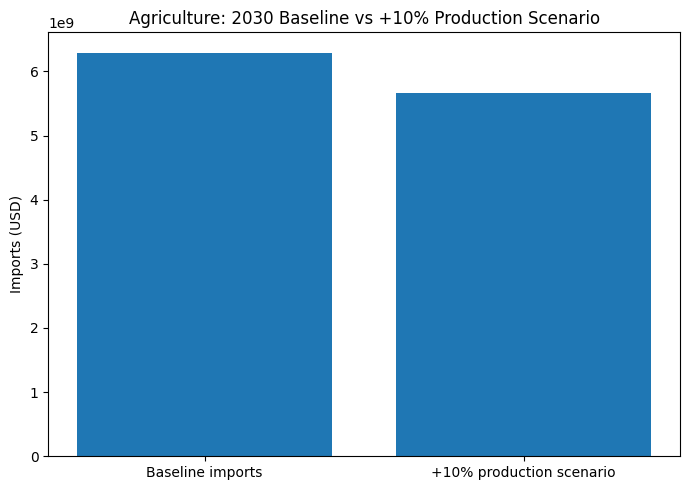

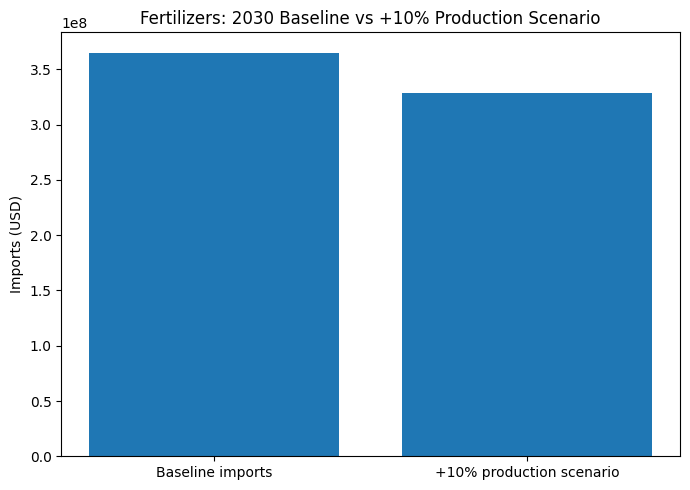

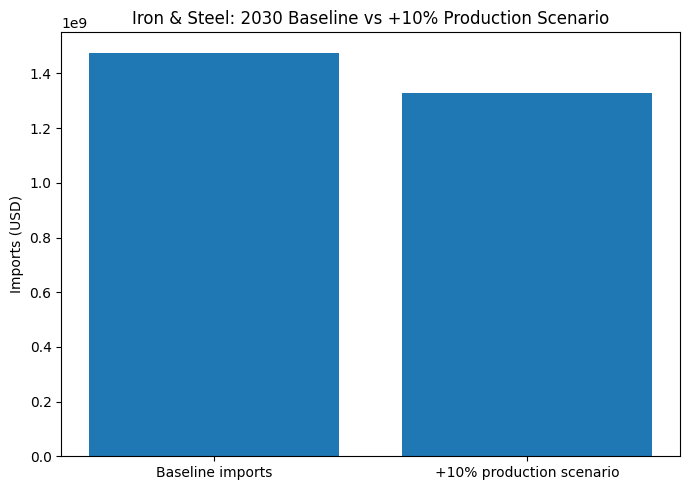

In [24]:
plot_df = base_10_df.sort_values(['Sector', 'Year']).copy()

# Only 2030 is plotted.
for sector in plot_df['Sector'].unique():
    d = plot_df[
        plot_df['Sector'].eq(sector) &
        plot_df['Year'].eq(2030)
    ]

    plt.figure(figsize=(7, 5))
    plt.bar(
        ['Baseline imports', '+10% production scenario'],
        [
            d['Baseline_Imports_USD'].iloc[0],
            d['Scenario_Imports_USD'].iloc[0]
        ]
    )
    plt.title(f'{sector}: 2030 Baseline vs +10% Production Scenario')
    plt.ylabel('Imports (USD)')
    plt.tight_layout()
    plt.show()


In [25]:
validation_df = (
    pd.concat(validation_tables, ignore_index=True)
    if validation_tables
    else pd.DataFrame()
)


# 2. Create DATA QUALITY table if it does not already exist
if 'data_quality_df' not in globals():

    data_quality_rows = []

    for sector, df in sector_data.items():

        data_quality_rows.append({
            'Sector': sector,
            'Observations': len(df),
            'Start_Year': int(df['year'].min()),
            'End_Year': int(df['year'].max()),
            'Missing_Production': int(
                df['production_t'].isna().sum()
            ),
            'Missing_Imports': int(
                df['imports_usd'].isna().sum()
            ),
            'Production_Min_t': float(
                df['production_t'].min()
            ),
            'Production_Max_t': float(
                df['production_t'].max()
            ),
            'Imports_Min_USD': float(
                df['imports_usd'].min()
            ),
            'Imports_Max_USD': float(
                df['imports_usd'].max()
            )
        })

    data_quality_df = pd.DataFrame(data_quality_rows)


# 3. Final results
final_results = (
    base_10_df
    .sort_values(['Sector', 'Year'])
    .groupby('Sector', as_index=False)
    .tail(1)
    .merge(
        diagnostics_df[
            [
                'Sector',
                'Best_Model',
                'CV_MAE_USD',
                'CV_RMSE_USD',
                'CV_MAPE_pct',
                'Reliability_Flag'
            ]
        ],
        on='Sector',
        how='left'
    )
)


# 4. Executive Summary
executive = final_results[
    [
        'Sector',
        'Year',
        'Best_Model',
        'Baseline_Imports_USD',
        'Scenario_Imports_USD',
        'FX_Savings_USD',
        'Import_Reduction_pct',
        'Reliability_Flag'
    ]
].copy()

executive = executive.rename(
    columns={'Year': 'Forecast_Year'}
)


# ============================================================
# 5. SAVE TO EXCEL
# ============================================================

with pd.ExcelWriter(
    OUTPUT_FILE,
    engine='openpyxl'
) as writer:

    executive.to_excel(
        writer,
        sheet_name='EXECUTIVE_SUMMARY',
        index=False
    )

    final_results.to_excel(
        writer,
        sheet_name='BASE_10PCT_SCENARIO',
        index=False
    )

    scenario_df.to_excel(
        writer,
        sheet_name='SCENARIO_ANALYSIS',
        index=False
    )

    scenario_df.to_excel(
        writer,
        sheet_name='FORECAST_2030_ONLY',
        index=False
    )

    validation_df.to_excel(
        writer,
        sheet_name='MODEL_VALIDATION',
        index=False
    )

    diagnostics_df.to_excel(
        writer,
        sheet_name='MODEL_DIAGNOSTICS',
        index=False
    )

    data_quality_df.to_excel(
        writer,
        sheet_name='DATA_QUALITY',
        index=False
    )

    cumulative_10.to_excel(
        writer,
        sheet_name='SUMMARY_2030',
        index=False
    )

    export_df.to_excel(
        writer,
        sheet_name='EXPORT_OPPORTUNITY',
        index=False
    )

    trade_df.to_excel(
        writer,
        sheet_name='TRADE_BALANCE',
        index=False
    )


    # --------------------------------------------------------
    # Partner outputs
    # --------------------------------------------------------

    for sector, q in partner_outputs.items():

        if q is not None and not q.empty:

            safe = (
                sector
                .replace('&', 'and')
                .replace(' ', '_')[:24]
            )

            q.to_excel(
                writer,
                sheet_name=f'PARTNERS_{safe}'[:31],
                index=False
            )


    # --------------------------------------------------------
    # Raw sector data
    # --------------------------------------------------------

    for sector, df in sector_data.items():

        safe = (
            sector
            .replace('&', 'and')
            .replace(' ', '_')[:25]
        )

        df.to_excel(
            writer,
            sheet_name=f'RAW_{safe}'[:31],
            index=False
        )


# ============================================================
# 6. VERIFY OUTPUT
# ============================================================

print('=' * 70)
print('FINAL MODEL COMPLETED SUCCESSFULLY')
print('=' * 70)

print('Output:', OUTPUT_FILE.resolve())

print('Sheets:')

with pd.ExcelFile(OUTPUT_FILE) as xls:

    for s in xls.sheet_names:
        print(' ✓', s)


# Display Executive Summary
display(executive)

FINAL MODEL COMPLETED SUCCESSFULLY
Output: /content/EGYPT_2030_IMPROVED_FINAL.xlsx
Sheets:
 ✓ EXECUTIVE_SUMMARY
 ✓ BASE_10PCT_SCENARIO
 ✓ SCENARIO_ANALYSIS
 ✓ FORECAST_2030_ONLY
 ✓ MODEL_VALIDATION
 ✓ MODEL_DIAGNOSTICS
 ✓ DATA_QUALITY
 ✓ SUMMARY_2030
 ✓ EXPORT_OPPORTUNITY
 ✓ TRADE_BALANCE
 ✓ PARTNERS_Agriculture
 ✓ PARTNERS_Fertilizers
 ✓ PARTNERS_Iron_and_Steel
 ✓ RAW_Agriculture
 ✓ RAW_Fertilizers
 ✓ RAW_Iron_and_Steel


,Sector,Forecast_Year,Best_Model,Baseline_Imports_USD,Scenario_Imports_USD,FX_Savings_USD,Import_Reduction_pct,Reliability_Flag
0,Agriculture,2030,Ridge,6.293665e+09,5.664299e+09,6.293665e+08,10.0,LOW_SAMPLE
1,Fertilizers,2030,NaiveLastImport,3.652399e+08,3.287159e+08,3.652399e+07,10.0,LOW_SAMPLE
2,Iron & Steel,2030,NaiveLastImport,1.476541e+09,1.328887e+09,1.476541e+08,10.0,LOW_SAMPLE
